# 03 Wetland: mangrove extent on the Ten Thousand Islands coast, 2020 to 2024

This notebook walks through the `wetland` app of `tessera_apps` on its bundled demo: a box of about
30 km x 24 km (81.62 W to 81.32 W, 25.75 N to 25.97 N) over the Ten Thousand Islands and the northern edge of
Everglades National Park, Collier County, Florida. It lies in one UTM zone group of the store, 17N, and covers
73,237 ha. ESA WorldCover 2020 maps it as 32.7% mangrove, 13.2% herbaceous wetland, 47.4% open water and 6.0% tree
cover.

Everything runs on the TESSERA v1.1 annual embeddings: one 128-dimensional int8 vector per 10 m pixel per year,
read anonymously from the public Icechunk store. No GPU, no credentials, and nothing is trained: the score is a
cosine distance to the mean of a few seed pixels.

The years are 2020 and 2024, not the brief's 2018 and 2024. The brief validates against Global Mangrove Watch
(GMW), whose host (zenodo.org) is blocked from the build environment. The reachable mangrove reference is ESA
WorldCover, which exists for 2020 (v100) and 2021 (v200) only, so `year_a` moved to 2020.

## 1. What the app answers

**Given a few confirmed locations of a wetland type, where else is it, and how has its extent moved?**

The method, as the brief's section 4.3 was corrected by the pre-build survey (B5, B6, S15, N9, N10):

1. **Seeds.** Points or polygons of the wetland type, in any CRS, inside or outside the AOI. A point samples the
   pixel it falls in; a polygon samples every pixel centre inside it. Pixels with no data, repeated pixels and
   pixels in a different radar regime from the AOI's majority (survey B5) are dropped. Fewer than 5 valid seed
   pixels stop the run before the AOI is read.
2. **Score.** The reference vector is the mean of the dequantized seed vectors. The default score is
   `1 - cosine similarity` to it, so lower is more seed-like. A Mahalanobis score under a Ledoit-Wolf shrunk
   covariance is allowed only with 500 or more seed pixels (survey B6: in 128 dimensions the covariance of fewer
   pixels is singular, and its inverse meaningless).
3. **Threshold from held-out seed scores** (survey B6). The seed pixels are grouped into spatial blocks (2 km grid
   cells, and seeds that touch), and the blocks into 5 folds. Each fold is scored against a reference fitted on
   the other four, and the threshold is the 95th percentile of the pooled held-out scores. The brief's rule, the
   95th percentile of the seeds' own (in-sample) scores, is reported next to it.
4. **Extent**, both years, with the same reference and the same threshold: score at or below the threshold, on
   pixels valid and in the seeds' radar regime in both years. Then a 3 x 3 opening and patches of at least 0.1 ha.
   Gain is extent in `year_b` only; loss is extent in `year_a` only.
5. **Coastal fraction.** The share of each year's extent within 1 km of the shoreline: Natural Earth 10 m by
   default, which is approximate here (survey N9).
6. **Validation.** Each year WorldCover maps is scored against its class 95 (mangroves), over AOI pixels where
   WorldCover has data, leaving out the seed pixels and everything within 200 m of them, from both recall and
   precision. The report gives recall (the brief's checkpoint metric), precision, IoU, F1 and the WorldCover
   class of every false positive.

Outputs: a float32 COG with five bands (`score_2020`, `score_2024`, `extent_2020`, `extent_2024`, `change`), a
summary table (parquet and csv, one row per year), every seed pixel with its fold and scores (parquet), a preview
PNG, a validation JSON, and a report JSON with provenance, timings and bytes read.

In [1]:
from __future__ import annotations

import logging
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
from scipy import ndimage

import tessera_apps
from tessera_apps import demo, io, metrics, validate
from tessera_apps.apps import AppInputError, load_aoi, run_wetland, wetland

# Show the app's own log lines (the run plan, "outputs are current", bytes read).
_handler = logging.StreamHandler()
_handler.setFormatter(logging.Formatter("%(levelname)s %(name)s: %(message)s"))
_log = logging.getLogger("tessera_apps")
_log.handlers[:] = [_handler]
_log.setLevel(logging.INFO)
_log.propagate = False

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72, "font.size": 10})
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

OUT = Path("out/wetland")
OUT21 = Path("out/wetland_2021")
PCA_CACHE = Path("out/wetland_pca_2020.npz")
YEAR_A, YEAR_B = 2020, 2024
STEP = 4  # overview images show every fourth pixel (a 40 m display grid)
GREY = "#d9d9d9"
WC_NAMES = validate.WORLDCOVER_CLASSES
print("tessera_apps", tessera_apps.__version__)

tessera_apps 0.1.0


## 2. The seeds

The brief asks for "12 points inside known mangrove stands from GMW". Two things changed:

- **Polygons, not points.** Twelve points are twelve pixels. That is too few for a held-out threshold, and far
  too few for any covariance (survey B6). The bundled seeds are 12 squares of 10 x 10 pixels (100 m), 1,200
  pixels in all, which also clears the 500-pixel bar for the Mahalanobis option.
- **WorldCover, not GMW.** GMW cannot be reached from here, so `scripts/make_everglades_seeds.py` derives the
  stands from WorldCover 2020 class 95. It erodes the class by 5 pixels (about 50 m) to keep stand interiors,
  splits the AOI into a 4 x 3 grid, takes the largest eroded component in each cell, and places one square
  wholly inside it.

The cost of the second change is honesty: **the seeds and the validation reference come from the same product**.
The 200 m buffer keeps the seed stands themselves out of the score, but the reference vector and the threshold
were still learned from WorldCover's own idea of a mangrove. So the scores in section 5 measure how well the
embeddings reproduce WorldCover's mangrove class from a few of its pixels, which is a consistency check rather than
an independent accuracy. Replace the seeds with GMW stands or field points wherever zenodo.org is reachable.

In [2]:
seeds_fc = demo.demo_seeds("everglades")
seeds_gdf = gpd.GeoDataFrame.from_features(seeds_fc["features"], crs="EPSG:4326")
props = seeds_fc["features"][0]["properties"]
print("source:", props["source"])
print("note:", props["note"])
b = seeds_gdf.geometry.bounds
display(
    pd.DataFrame(
        {
            "seed": seeds_gdf["seed_id"],
            "grid cell": seeds_gdf["grid_cell"],
            "pixels": seeds_gdf["pixels"],
            "eroded stand (ha)": seeds_gdf["component_pixels_eroded"] / 100,
            "lon": ((b.minx + b.maxx) / 2).round(4),
            "lat": ((b.miny + b.maxy) / 2).round(4),
        }
    ).set_index("seed")
)

source: ESA WorldCover 2020 v100, class 95 (mangroves)
note: These seeds and the default WorldCover validation reference come from the same product, so the wetland app's score against WorldCover is not independent of its seeds. Global Mangrove Watch stands should replace them where zenodo.org is reachable (it is blocked from the build environment).


,grid cell,pixels,eroded stand (ha),lon,lat
seed,,,,,
1,row 0 col 0,100,4426.88,-81.561,25.938
2,row 0 col 1,100,9.41,-81.474,25.921
3,row 0 col 2,100,9.90,-81.396,25.901
4,row 0 col 3,100,3.18,-81.392,25.901
5,row 1 col 0,100,62.09,-81.560,25.868
6,row 1 col 1,100,90.10,-81.542,25.863
7,row 1 col 2,100,3901.13,-81.451,25.895
8,row 1 col 3,100,2735.39,-81.350,25.839
9,row 2 col 1,100,21.99,-81.471,25.820


The map below is a PCA false colour of the 2020 embeddings: three principal components of the AOI's dequantized
vectors, shown as red, green and blue. It is the cheapest way to see what the embeddings separate. The cell
streams 2020 for every AOI chunk once (about 1.2 GB) and caches the small images in `out/wetland_pca_2020.npz`, so
running the notebook again does not read the store for it. Mangrove reads as one colour family (blue) along the coast,
around the islands and up the rivers; open water, the marsh inland and the woody upland each get their own. The
diagonal step across the open Gulf, bottom left, is most likely the edge between two satellite swaths in the input
imagery: the embeddings keep it over water, and it does not reach the land.

In [3]:
reader = io.TesseraReader.open()  # metadata only, until the PCA read below
aoi = load_aoi("everglades")
plan = io.plan_aoi(reader, aoi.geometry)
zp = plan.zones[0]
H, W = zp.shape
T = zp.transform
EXTENT = (T.c, T.c + W * T.a, T.f + H * T.e, T.f)  # left, right, bottom, top (metres, EPSG:32617)
CRS = f"EPSG:{zp.grid.epsg}"
seeds_utm = seeds_gdf.to_crs(CRS)
sb = seeds_utm.geometry.bounds
seed_rc = np.stack([((T.f - sb.maxy) / 10).round(), ((sb.minx - T.c) / 10).round()], axis=1).astype(int)
CROP = 48  # inset side in pixels (480 m)
crops = [(int(r) + 5 - CROP // 2, int(c) + 5 - CROP // 2) for r, c in seed_rc]
print(f"zone {zp.zone}: window {H} x {W} pixels, {zp.n_pixels:,} in the AOI")


def pca_false_colour(year: int, step: int) -> dict[str, np.ndarray]:
    """Stream one year of the AOI; PCA colours at every ``step``-th pixel and at 10 m in the seed insets."""
    r0, c0 = zp.rows.start, zp.cols.start
    emb = np.zeros((-(-H // step), -(-W // step), 128), np.int8)
    sc = np.full(emb.shape[:2], np.nan, np.float32)
    cemb = np.zeros((len(crops), CROP, CROP, 128), np.int8)
    csc = np.full((len(crops), CROP, CROP), np.nan, np.float32)
    before, t0 = reader.bytes_read, time.perf_counter()
    for blk in io.iter_plan_blocks(reader, zp, [year], layers=("embeddings", "scales")):
        win = blk.windows[year]
        e, s = win.embeddings, np.where(blk.mask, win.scales, np.nan)
        lr, lc = blk.rows.start - r0, blk.cols.start - c0
        fr, fc = (-lr) % step, (-lc) % step
        se, ss = e[fr::step, fc::step], s[fr::step, fc::step]
        orow, ocol = (lr + fr) // step, (lc + fc) // step
        emb[orow : orow + se.shape[0], ocol : ocol + se.shape[1]] = se
        sc[orow : orow + ss.shape[0], ocol : ocol + ss.shape[1]] = ss
        for k, (cr, cc) in enumerate(crops):
            ra, rb = max(cr, lr), min(cr + CROP, lr + e.shape[0])
            ca, cb = max(cc, lc), min(cc + CROP, lc + e.shape[1])
            if ra < rb and ca < cb:
                cemb[k, ra - cr : rb - cr, ca - cc : cb - cc] = e[ra - lr : rb - lr, ca - lc : cb - lc]
                csc[k, ra - cr : rb - cr, ca - cc : cb - cc] = s[ra - lr : rb - lr, ca - lc : cb - lc]
    x = emb.astype(np.float32) * sc[..., None]
    ok = np.isfinite(sc)
    basis = metrics.fit_pca(x, ok, sample=100_000, seed=0)
    rgb = metrics.pca_rgb(x, basis, mask=ok)
    inset = np.stack(
        [
            metrics.pca_rgb(ce.astype(np.float32) * cs[..., None], basis, mask=np.isfinite(cs))
            for ce, cs in zip(cemb, csc, strict=True)
        ]
    )
    return {
        "rgb": rgb,
        "insets": inset,
        "crops": np.asarray(crops),
        "step": np.asarray(step),
        "bytes_read": np.asarray(reader.bytes_read - before),
        "seconds": np.asarray(time.perf_counter() - t0),
    }


cached = None
if PCA_CACHE.is_file():
    with np.load(PCA_CACHE) as f:
        cached = {k: f[k] for k in f.files}
    if int(cached["step"]) != STEP or not np.array_equal(cached["crops"], np.asarray(crops)):
        cached = None
if cached is None:
    cached = pca_false_colour(YEAR_A, STEP)
    PCA_CACHE.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(PCA_CACHE, **cached)
    print("computed the PCA false colour now:", end=" ")
else:
    print("PCA false colour loaded from the cache; when it was computed it", end=" ")
print(f"read {int(cached['bytes_read']) / 1e9:.2f} GB in {float(cached['seconds']):.0f} s")
wc = {y: validate.worldcover_map(zp, y) for y in (2020, 2021)}  # cached by the app's validating runs

zone 17N: window 2448 x 3015 pixels, 7,323,696 in the AOI
PCA false colour loaded from the cache; when it was computed it read 1.06 GB in 28 s


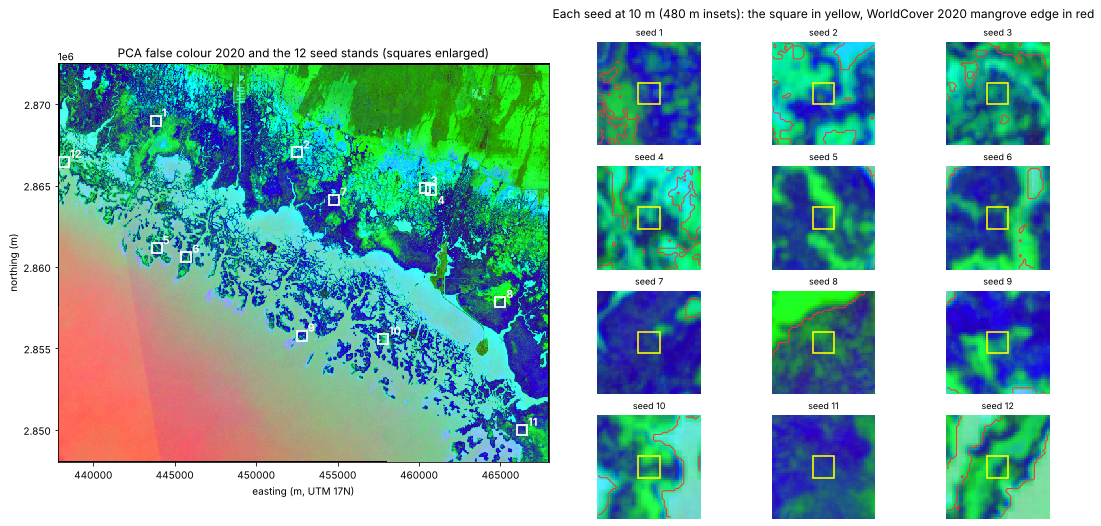

In [4]:
fig = plt.figure(figsize=(15, 7.2), layout="constrained")
left, right = fig.subfigures(1, 2, width_ratios=[1.05, 1])
ax = left.subplots()
ax.imshow(cached["rgb"], extent=EXTENT, interpolation="nearest")
cx, cy = (sb.minx + sb.maxx) / 2, (sb.miny + sb.maxy) / 2
ax.plot(cx, cy, "s", mfc="none", mec="white", ms=10, mew=1.8)
for sid, x, y in zip(seeds_gdf["seed_id"], cx, cy, strict=True):
    offset = (6, -14) if sid == 4 else (6, 4)  # seeds 3 and 4 are 400 m apart
    ax.annotate(str(sid), (x, y), xytext=offset, textcoords="offset points", color="white", fontsize=11, weight="bold")
ax.set_title(f"PCA false colour {YEAR_A} and the 12 seed stands (squares enlarged)")
ax.set_xlabel("easting (m, UTM 17N)")
ax.set_ylabel("northing (m)")
axes = right.subplots(4, 3)
for k, a in enumerate(axes.ravel()):
    cr, cc = crops[k]
    a.imshow(cached["insets"][k], interpolation="nearest")
    mang = (wc[2020][cr : cr + CROP, cc : cc + CROP] == 95).astype(float)
    if 0 < mang.mean() < 1:
        a.contour(mang, levels=[0.5], colors=["#ff3030"], linewidths=1.0)
    off = CROP // 2 - 5 - 0.5
    a.add_patch(Rectangle((off, off), 10, 10, fill=False, ec="yellow", lw=1.6))
    a.set_title(f"seed {seeds_gdf['seed_id'].iloc[k]}", fontsize=9)
    a.set_axis_off()
right.suptitle("Each seed at 10 m (480 m insets): the square in yellow, WorldCover 2020 mangrove edge in red")
plt.show()

Every square sits wholly inside an eroded WorldCover stand, at least 50 m from its edge, by construction. The
stands range from 3 ha (seed 4) to about 4,400 ha (seed 1) after erosion, and seeds 3 and 4 lie only about 400 m
apart. Interior squares are clean seeds, and also a narrow sample: they are the inside of stands, not the thin,
mixed mangrove along creeks and the landward edge, which is where section 5 finds most of the disagreement.

## 3. Run it

From a shell, the same run is one command. This is how the outputs used below were produced, from a container
outside `us-west-2` with no AWS credentials (`AWS_ACCESS_KEY_ID`, `AWS_SECRET_ACCESS_KEY` and
`AWS_SESSION_TOKEN` cleared):

```
tessera-apps wetland --aoi everglades --year-a 2020 --year-b 2024 --out notebooks/out/wetland --validate
```

With `--aoi everglades` and no `--seeds`, the bundled seeds are used. In Python it is one call. The run reads 2020
and 2024 for every AOI chunk, plus the 12 seed chunks in both years and a radar regime probe (2.37 GB in all,
section 9). It is idempotent: when `out/wetland` already holds outputs that the report says were written with the
same arguments, AOI, seeds, code and store snapshot, the call reads only the store's metadata and returns at once
with `skipped` set. Delete the directory or pass `force=True` to recompute.

In [5]:
t0 = time.perf_counter()
result = run_wetland("everglades", YEAR_A, YEAR_B, OUT, validate=True)
report, summary = result.report, result.summary
val = summary["validation"]
print(f"skipped (outputs current): {result.skipped}, in {time.perf_counter() - t0:.1f} s")
for path in [
    result.paths.tif,
    result.paths.summary_parquet,
    result.paths.summary_csv,
    *result.extra_paths.values(),
    result.paths.preview,
    result.paths.validation,
    result.paths.report,
]:
    print(f"  {path.name:28s} {path.stat().st_size / 1e6:8.2f} MB")

INFO tessera_apps.apps._common: wetland: AOI demo:everglades, 73,237 ha in 1 zone(s) (17N 2448 x 3015), 7,323,696 pixels; years 2020, 2024; at most 3.58 GB of chunks to read.


INFO tessera_apps.apps._common: wetland: peak memory about 1.6 GB (14.5 GB available).


INFO tessera_apps.apps.wetland: wetland: 1200 seed pixels (12 polygon features, 0 points) in 12 chunks of 17N, at most 0.22 GB to read for them.


INFO tessera_apps.apps._common: wetland: removed the previous run's wetland_report.json, wetland_validation.json.


INFO tessera_apps.io: read_points: 1200 points from 12 chunks


INFO tessera_apps.io: read_points: 1200 points from 12 chunks


INFO tessera_apps.apps._common: wetland: read 2.37 GB in 97.7 s (24 MB/s).


skipped (outputs current): False, in 97.8 s
  wetland_2020_2024.tif           81.59 MB
  wetland_summary.parquet          0.01 MB
  wetland_summary.csv              0.00 MB
  wetland_seeds.parquet            0.06 MB
  wetland_preview.png              1.29 MB
  wetland_validation.json          0.00 MB
  wetland_report.json              0.01 MB


In [6]:
seeds_rec, thr_rec, radar = summary["seeds"], summary["threshold"], summary["radar"]
thr, thr_in = thr_rec["threshold"], thr_rec["in_sample_percentile"]
pd.Series(
    {
        "AOI area (ha)": f"{summary['aoi_area_ha']:,.0f}",
        "zone": ", ".join(summary["zones"]),
        "classified pixels (both years)": f"{summary['classified_pixels']:,} of {summary['aoi_pixels']:,}",
        "seed pixels used": f"{seeds_rec['used']:,} of {seeds_rec['pixels']:,} "
        f"({seeds_rec['polygon_features_used']} polygons, {seeds_rec['spatial_blocks']} spatial blocks, "
        f"{thr_rec['folds']} folds)",
        "score": summary["score"]["type"],
        "threshold (held-out p95)": f"{thr:.4f}",
        "in-sample p95 (the brief's rule)": f"{thr_in:.4f}",
        f"extent {YEAR_A}": f"{summary['extent_ha_year_a']:,.0f} ha",
        f"extent {YEAR_B}": f"{summary['extent_ha_year_b']:,.0f} ha",
        "net change": f"{summary['net_change_ha']:+,.0f} ha ({summary['net_change_pct']:+.1f}%)",
        "gain / loss": f"{summary['gain_ha']:,.0f} ha / {summary['loss_ha']:,.0f} ha",
        "coastal fraction (within 1 km)": f"{summary['coastal_fraction_year_a']:.1%} in {YEAR_A}, "
        f"{summary['coastal_fraction_year_b']:.1%} in {YEAR_B}",
        "radar": f"seeds {radar['seed_regime']}, regime mismatch {radar['regime_mismatch_fraction']:.1%}",
        f"recall vs WorldCover {val['year']} (seeds excluded)": f"{val['recall']:.3f}",
        "precision / IoU / F1": f"{val['precision']:.3f} / {val['iou']:.3f} / {val['f1']:.3f}",
    },
    name="value",
).to_frame()

,value
AOI area (ha),"73,237"
zone,17N
classified pixels (both years),"7,323,620 of 7,323,696"
seed pixels used,"1,200 of 1,200 (12 polygons, 11 spatial blocks, 5 folds)"
score,cosine
threshold (held-out p95),0.2955
in-sample p95 (the brief's rule),0.2794
extent 2020,"22,813 ha"
extent 2024,"24,979 ha"
net change,"+2,166 ha (+9.5%)"


## 4. The score map and the seed scores

The score is `1 - cosine` to the mean 2020 seed vector. On the map, low scores (yellow) are seed-like: they follow
the coast, the islands and the rivers. Water, marsh and the woody upland score from about 0.35 to 0.65 (teal to
blue). The colour bar is cut at three times the threshold, which is marked on it in red.

The histogram is the threshold's whole story. Each seed pixel is scored twice: in sample (against a reference
that includes it) and held out (against a reference fitted on the other four folds, so its own stand did not
shape the mean). The threshold is the 95th percentile of the held-out scores.

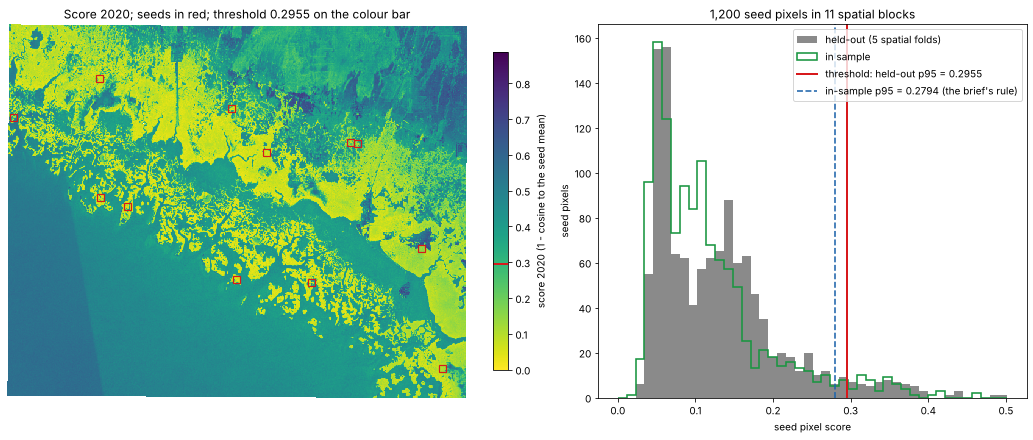

held-out pixels within the threshold: 95.0%; in sample: 95.8%; in 2024: 100.0%


,fold,median_in_sample,median_heldout,heldout_within_threshold,median_2024
seed,,,,,
1,1,0.060,0.064,1.00,0.096
2,2,0.083,0.086,0.97,0.120
3,4,0.103,0.125,1.00,0.147
4,4,0.147,0.169,0.98,0.149
5,4,0.073,0.070,0.94,0.105
6,2,0.053,0.060,1.00,0.093
7,0,0.050,0.056,1.00,0.094
8,3,0.140,0.174,1.00,0.166
9,0,0.084,0.100,0.97,0.067


In [7]:
def read_bands(path: Path) -> dict[str, np.ndarray]:
    """Every band of a run's COG, by its description, after checking it is on the plan's grid."""
    with rasterio.open(path) as src:
        assert src.shape == (H, W) and src.transform.almost_equals(T), (src.shape, src.transform)
        return {d: src.read(i + 1) for i, d in enumerate(src.descriptions)}


B = read_bands(result.paths.tif)
seed_px = pd.read_parquet(result.extra_paths["seeds"])
used = seed_px["used"].to_numpy()
held, ins = seed_px.loc[used, "score_heldout"].to_numpy(), seed_px.loc[used, "score_in_sample"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.2, 1]}, layout="constrained")
im = axes[0].imshow(
    np.ma.masked_invalid(B[f"score_{YEAR_A}"][::STEP, ::STEP]),
    cmap="viridis_r",
    vmin=0,
    vmax=3 * thr,
    extent=EXTENT,
    interpolation="nearest",
)
bar = fig.colorbar(im, ax=axes[0], shrink=0.85, label=f"score {YEAR_A} (1 - cosine to the seed mean)")
bar.ax.axhline(thr, color="#d7191c", lw=2)
axes[0].plot(cx, cy, "s", mfc="none", mec="#d7191c", ms=7, mew=1.2)
axes[0].set_title(f"Score {YEAR_A}; seeds in red; threshold {thr:.4f} on the colour bar")
axes[0].set_axis_off()
bins = np.linspace(0, max(held.max(), ins.max()) * 1.02, 45)
axes[1].hist(held, bins=bins, color="#636363", alpha=0.75, label=f"held-out ({thr_rec['folds']} spatial folds)")
axes[1].hist(ins, bins=bins, histtype="step", color="#1a9641", lw=1.6, label="in sample")
axes[1].axvline(thr, color="#d7191c", lw=2, label=f"threshold: held-out p95 = {thr:.4f}")
axes[1].axvline(thr_in, color="#2166ac", ls="--", lw=1.6, label=f"in-sample p95 = {thr_in:.4f} (the brief's rule)")
axes[1].set_xlabel("seed pixel score")
axes[1].set_ylabel("seed pixels")
axes[1].set_title(f"{used.sum():,} seed pixels in {seeds_rec['spatial_blocks']} spatial blocks")
axes[1].legend()
plt.show()

per_seed = (
    seed_px[used]
    .assign(seed=lambda d: d["feature"] + 1)
    .groupby("seed")
    .agg(
        fold=("fold", "first"),
        median_in_sample=("score_in_sample", "median"),
        median_heldout=("score_heldout", "median"),
        heldout_within_threshold=("score_heldout", lambda s: float(np.mean(s <= thr))),
        median_2024=("score_year_b", "median"),
    )
)
print(
    f"held-out pixels within the threshold: {seeds_rec['share_heldout_within_threshold']:.1%}; "
    f"in sample: {seeds_rec['share_in_sample_within_threshold']:.1%}; "
    f"in {YEAR_B}: {seeds_rec['share_year_b_within_threshold']:.1%}"
)
per_seed

Three readings:

- **The held-out threshold is only a little looser than the in-sample one here**: 0.2955 against 0.2794. The
  survey's experiment (B6) found a much bigger gap, but there the seeds were k-means clusters, not 12 similar
  interior stands. When every stand looks like the others, leaving one out barely moves the mean.
- **The seeds are not equally typical.** Held-out medians run from 0.056 (seed 7) to 0.211 (seed 12), and seeds
  12 and 10 hold 46 of the 60 held-out pixels above the threshold. A stand that the other eleven do not describe is
  exactly what a held-out score should expose. Seed 12 is the stand the seed script took to fill an empty grid
  cell, at the AOI's west edge. It is also the seed that changes most by 2024 (median 0.205 in 2020, 0.088 in 2024),
  the same pattern as the large missed stands of section 6.
- **Folds are spatial blocks, not pixels.** Seeds 3 and 4 share a 2 km cell, so 12 polygons give 11 blocks,
  spread over 5 folds.

## 5. Extent 2020 over WorldCover 2020 mangrove

Agreement and disagreement on one map: green where both say mangrove, orange where only the app does (false
positives against WorldCover), purple where only WorldCover does (misses). Black marks the seeds and the 200 m
buffer around them, which the score leaves out. The right panel is a 4 km x 4 km window at 10 m, the window with
the most disagreement.

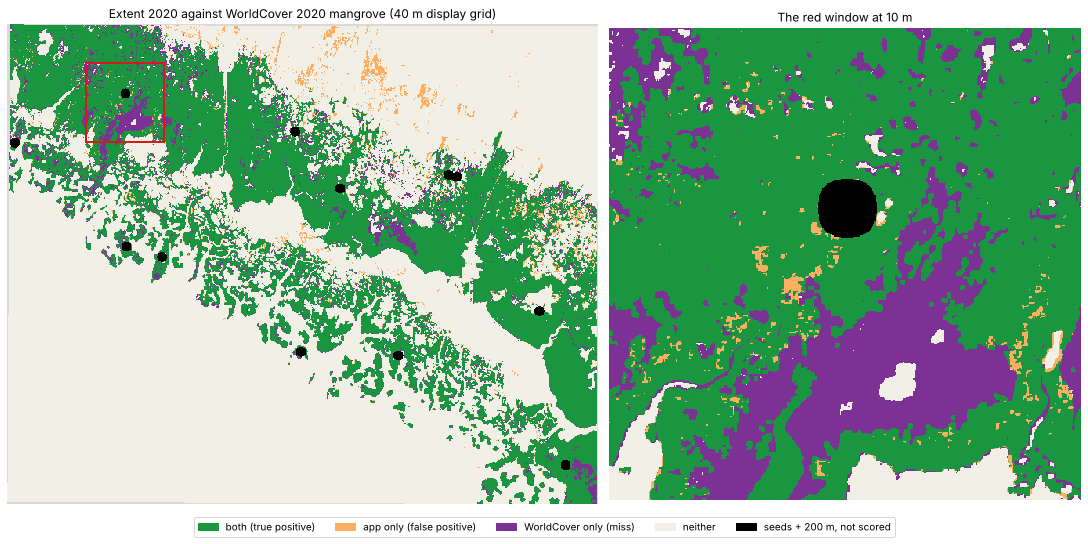

In [8]:
classified = np.isfinite(B["change"])
ext = {YEAR_A: B[f"extent_{YEAR_A}"] == 1, YEAR_B: B[f"extent_{YEAR_B}"] == 1}
mang = {y: (wc[y] == validate.WORLDCOVER_MANGROVE) & zp.mask for y in wc}
on_grid = seed_px[seed_px["row"] >= 0]
excl = wetland.seed_exclusion(zp, on_grid[["lon", "lat"]].to_numpy(), val["seed_buffer_m"])
scored = classified & (wc[2020] != 0) & zp.mask & ~excl
tp, fn, fp = ext[YEAR_A] & mang[2020] & scored, ~ext[YEAR_A] & mang[2020] & scored, ext[YEAR_A] & ~mang[2020] & scored
recall, precision = tp.sum() / (tp.sum() + fn.sum()), tp.sum() / (tp.sum() + fp.sum())
assert abs(recall - val["recall"]) < 1e-9 and abs(precision - val["precision"]) < 1e-9  # same as the app's

cat = np.full((H, W), np.nan)
cat[scored] = 0
cat[tp], cat[fp], cat[fn] = 1, 2, 3
cat[excl & zp.mask] = 4
CAT_CMAP = ListedColormap(["#f2f0e6", "#1a9641", "#fdae61", "#7b3294", "#000000"]).with_extremes(bad=GREY)
# The 400 x 400 pixel window with the most disagreement, on a 200-pixel lattice.
err = (fp | fn).astype(np.int32)
best = max(
    ((r, c) for r in range(0, H - 400, 200) for c in range(0, W - 400, 200)),
    key=lambda rc: int(err[rc[0] : rc[0] + 400, rc[1] : rc[1] + 400].sum()),
)
zr, zc = best
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.25, 1]}, layout="constrained")
axes[0].imshow(cat[::STEP, ::STEP], cmap=CAT_CMAP, vmin=-0.5, vmax=4.5, extent=EXTENT, interpolation="nearest")
x0, y0 = T.c + zc * 10, T.f - (zr + 400) * 10
axes[0].add_patch(Rectangle((x0, y0), 4000, 4000, fill=False, ec="#d7191c", lw=2))
axes[0].set_title(f"Extent {YEAR_A} against WorldCover {YEAR_A} mangrove (40 m display grid)")
axes[0].set_axis_off()
axes[1].imshow(cat[zr : zr + 400, zc : zc + 400], cmap=CAT_CMAP, vmin=-0.5, vmax=4.5, interpolation="nearest")
axes[1].set_title("The red window at 10 m")
axes[1].set_axis_off()
fig.legend(
    handles=[
        Patch(color="#1a9641", label="both (true positive)"),
        Patch(color="#fdae61", label="app only (false positive)"),
        Patch(color="#7b3294", label="WorldCover only (miss)"),
        Patch(color="#f2f0e6", label="neither"),
        Patch(color="#000000", label="seeds + 200 m, not scored"),
    ],
    loc="lower center",
    ncols=5,
    bbox_to_anchor=(0.5, -0.06),
)
plt.show()

In [9]:
row = val["per_year"][str(YEAR_A)]
display(
    pd.DataFrame(
        {
            "recall": [f"{row['recall']:.4f}", f"{row['recall_with_seeds']:.4f}"],
            "precision": [f"{row['precision']:.4f}", f"{row['precision_with_seeds']:.4f}"],
            "IoU": [f"{row['iou']:.4f}", "not reported"],
            "F1": [f"{row['f1']:.4f}", "not reported"],
        },
        index=["seeds and 200 m excluded (headline)", "seeds left in"],
    )
)
print(
    f"scored {row['pixels_scored']:,} pixels: {row['reference_pixels_scored']:,} WorldCover mangrove, "
    f"{row['extent_pixels_scored']:,} app extent; {row['seed_excluded_pixels']:,} excluded around the seeds"
)
fpc = pd.DataFrame(row["false_positive_classes"]).T
d_out = ndimage.distance_transform_edt(~mang[2020]) * 10  # metres to the nearest WorldCover mangrove pixel
d_in = ndimage.distance_transform_edt(mang[2020]) * 10  # metres to the nearest non-mangrove pixel
fpc["within 20 m of WorldCover mangrove"] = [float(np.mean(d_out[fp & (wc[2020] == int(c))] <= 20)) for c in fpc.index]
fpc["median distance (m)"] = [float(np.median(d_out[fp & (wc[2020] == int(c))])) for c in fpc.index]
fpc = fpc.sort_values("pixels", ascending=False)
fpc["share"] = fpc["share"].astype(float).map("{:.1%}".format)
fpc["within 20 m of WorldCover mangrove"] = fpc["within 20 m of WorldCover mangrove"].map("{:.0%}".format)
fpc["median distance (m)"] = fpc["median distance (m)"].map("{:,.0f}".format)
print("False positives by WorldCover 2020 class:")
display(fpc[fpc["pixels"].astype(int) >= 100])

,recall,precision,IoU,F1
seeds and 200 m excluded (headline),0.8945,0.9398,0.8460,0.9166
seeds left in,0.8944,0.9400,not reported,not reported


scored 7,298,854 pixels: 2,376,088 WorldCover mangrove, 2,261,586 app extent; 24,766 excluded around the seeds


False positives by WorldCover 2020 class:


,name,pixels,share,within 20 m of WorldCover mangrove,median distance (m)
90,herbaceous wetland,56588,41.5%,66%,14
10,tree cover,46988,34.5%,21%,"1,481"
80,permanent water bodies,31568,23.2%,86%,10
50,built-up,480,0.4%,68%,14
30,grassland,299,0.2%,61%,14
60,bare or sparse vegetation,296,0.2%,53%,20


**Recall against WorldCover 2020 mangrove is 0.894, with precision 0.940, IoU 0.846 and F1 0.917.** That is the
checkpoint number. Nothing was tuned: the threshold is the held-out 95th percentile, every parameter is the
default, and the reference was fixed before the run. Leaving the seeds in barely moves recall (0.8944 against
0.8945), because 1,200 seed pixels are 0.05% of WorldCover's 2.4 million mangrove pixels here; the bigger
dependence on WorldCover is the one the buffer cannot remove (section 2).

The false positives fall in the three classes the method should confuse, and they are of two kinds:

- **Herbaceous wetland (42%) and water (23%) are edge effects.** Most of these pixels lie within 20 m of a
  WorldCover mangrove pixel: a 10 m pixel on a creek bank or on the landward fringe mixes mangrove canopy with
  water or marsh, and the two maps resolve the mix differently.
- **Tree cover (34%) is a real confusion.** These pixels lie a median of about 1.5 km from any WorldCover mangrove:
  inland woody vegetation (tree islands and hammocks in the marsh) that the embeddings put close to the seed
  mean. WorldCover's own split between "tree cover" and "mangroves" in a coastal swamp forest is itself a modelled
  decision.

The cell below looks at the misses the same way, and at how the classes' scores overlap.

In [10]:
idx = ndimage.distance_transform_edt(mang[2020], return_distances=False, return_indices=True)
nearest_other = wc[2020][idx[0], idx[1]]  # the WorldCover class just outside the stand each miss sits in
s_a = B[f"score_{YEAR_A}"]
edge = scored & (((mang[2020]) & (d_in <= 20)) | ((~mang[2020]) & (d_out <= 20)))
core = scored & ~edge
tpc, fnc, fpc_n = (tp & core).sum(), (fn & core).sum(), (fp & core).sum()
near_counts = pd.Series(nearest_other[fn]).map(lambda c: WC_NAMES.get(int(c), str(c))).value_counts(normalize=True)
miss_lab, _ = ndimage.label(fn, structure=np.ones((3, 3)))
miss_sizes = np.bincount(miss_lab.ravel())
miss_sizes[0] = 0
big_blocks = np.flatnonzero(miss_sizes >= 1000)  # 10 ha
pd.Series(
    {
        "misses within 20 m of a WorldCover mangrove edge": f"{np.mean(d_in[fn] <= 20):.1%}",
        "false positives within 20 m of WorldCover mangrove": f"{np.mean(d_out[fp] <= 20):.1%}",
        "recall away from the 20 m edge band": f"{tpc / (tpc + fnc):.3f}",
        "precision away from the 20 m edge band": f"{tpc / (tpc + fpc_n):.3f}",
        "misses with score <= threshold (removed by the opening or 0.1 ha)": f"{np.mean(s_a[fn] <= thr):.1%}",
        "misses within 0.05 above the threshold": f"{np.mean(s_a[fn] <= thr + 0.05):.1%}",
        "misses: nearest non-mangrove class": ", ".join(f"{k} {v:.0%}" for k, v in near_counts.head(3).items()),
        "misses in contiguous blocks of 10 ha or more": f"{np.mean(np.isin(miss_lab[fn], big_blocks)):.1%}",
    },
    name="value",
).to_frame()

,value
misses within 20 m of a WorldCover mangrove edge,43.9%
false positives within 20 m of WorldCover mangrove,55.0%
recall away from the 20 m edge band,0.931
precision away from the 20 m edge band,0.969
misses with score <= threshold (removed by the opening or 0.1 ha),4.9%
misses within 0.05 above the threshold,42.9%
misses: nearest non-mangrove class,"permanent water bodies 41%, herbaceous wetland 39%, tree cover 17%"
misses in contiguous blocks of 10 ha or more,27.6%


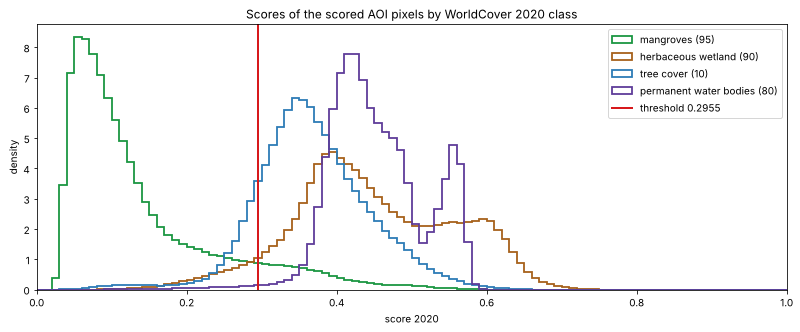

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
bins = np.linspace(0, 1.0, 101)
for code_, colour in ((95, "#1a9641"), (90, "#a6611a"), (10, "#2c7bb6"), (80, "#5e3c99")):
    m = scored & (wc[2020] == code_)
    ax.hist(
        s_a[m], bins=bins, density=True, histtype="step", lw=1.8, color=colour, label=f"{WC_NAMES[code_]} ({code_})"
    )
ax.axvline(thr, color="#d7191c", lw=2, label=f"threshold {thr:.4f}")
ax.set_xlim(0, 1.0)
ax.set_xlabel(f"score {YEAR_A}")
ax.set_ylabel("density")
ax.set_title(f"Scores of the scored AOI pixels by WorldCover {YEAR_A} class")
ax.legend()
plt.show()

Where the two maps disagree:

- **Edges dominate.** About 44% of the misses and 55% of the false positives lie within 20 m (two pixels) of a
  WorldCover mangrove edge. Away from that band, recall rises to 0.931 and precision to 0.969.
- **Misses border water and marsh.** A miss is a WorldCover mangrove pixel whose score is above the threshold;
  the class just outside its stand is open water or herbaceous wetland about 80% of the time. Many misses are
  close calls (43% score within 0.05 of the threshold), and about 5% scored under the threshold but were removed by
  the opening or the 0.1 ha minimum.
- **Some misses are whole stands.** About 28% of the misses lie in contiguous blocks of 10 ha or more, like the
  purple block in the zoom: WorldCover calls them mangrove, the embeddings put them well away from the seeds.
  Section 6 shows most of these blocks moving steadily toward the seeds by 2024, which looks like stands still
  damaged in 2020 that have since regrown.
- **The class histograms overlap where expected.** Most mangrove scores sit well below the threshold, with a long
  tail across it; water is well above it; herbaceous wetland and tree cover have tails reaching under it.
- **WorldCover is a model.** It is a 10 m land cover map made from Sentinel-1 and Sentinel-2 with its own errors,
  and its own mangrove edge is a decision about mixed pixels. Section 6 shows its 2020 (v100) and 2021 (v200) maps
  disagree on 3.7% of the scored pixels.

The brief's in-sample rule, for comparison only (the app does not use it): the same seeds with the in-sample 95th
percentile as the threshold.

In [12]:
def scores_at(threshold: float) -> dict[str, float]:
    """The 2020 extent at another threshold, cleaned the app's way, scored the app's way."""
    min_pixels = metrics.area_to_pixels(summary["min_area_ha"])
    m = metrics.clean_mask((s_a <= threshold) & classified, min_pixels=min_pixels) & zp.mask
    a, b_, c = (m & mang[2020] & scored).sum(), (~m & mang[2020] & scored).sum(), (m & ~mang[2020] & scored).sum()
    return {
        "threshold": threshold,
        "extent (ha)": m.sum() * io.HA_PER_PIXEL,
        "recall": a / (a + b_),
        "precision": a / (a + c),
        "IoU": a / (a + b_ + c),
    }


pd.DataFrame({"held-out p95 (the app)": scores_at(thr), "in-sample p95 (the brief's rule)": scores_at(thr_in)}).T

,threshold,extent (ha),recall,precision,IoU
held-out p95 (the app),0.295,22813.31,0.894,0.940,0.846
in-sample p95 (the brief's rule),0.279,22056.17,0.879,0.955,0.844


The in-sample threshold trades 1.6 points of recall for 1.5 of precision, and IoU is almost the same. At this site
the held-out rule matters less than survey B6 feared; it is still the right default, because it is the rule that
does not depend on how alike the seed stands happen to be.

## 6. Extent 2024, gain and loss, and the storms

**Storm context (survey N10).** Hurricane Irma's second Florida landfall, at Marco Island on 10 September 2017,
was just west of this AOI, and Irma caused about 10,760 ha of mangrove dieback across southwest Florida
(Lagomasino et al. 2021). Hurricane Ian (landfall at Cayo Costa, Lee County, 28 September 2022) hit the coast north
of the AOI. So 2020 is a post-Irma baseline: gain after it may be recovery from dieback, and loss by 2024 may be
Ian. The app's report carries the same note.

**Is the change real, or threshold noise?** A change map from two independent classifications always has some
flicker at the threshold. To see how much, the app also ran for 2020 to 2021: one year apart, with no major
hurricane in between, so the true change should be small. Its outputs are reused the same way (`out/wetland_2021`,
produced by the same CLI command with `--year-b 2021`).

In [13]:
result21 = run_wetland("everglades", YEAR_A, 2021, OUT21, validate=True)
s21 = result21.summary
B21 = read_bands(result21.paths.tif)
assert s21["threshold"]["threshold"] == thr  # same seeds, same reference, same threshold


def change_row(s: dict) -> dict[str, str]:
    """The change figures of one run's summary, formatted."""
    return {
        f"extent {s['year_a']} (ha)": f"{s['extent_ha_year_a']:,.0f}",
        "extent year_b (ha)": f"{s['extent_ha_year_b']:,.0f}",
        "net change": f"{s['net_change_ha']:+,.0f} ha ({s['net_change_pct']:+.1f}%)",
        "gain (ha)": f"{s['gain_ha']:,.0f}",
        "loss (ha)": f"{s['loss_ha']:,.0f}",
        "gross change, share of year_a extent": f"{(s['gain_ha'] + s['loss_ha']) / s['extent_ha_year_a']:.1%}",
        "seed pixels within the threshold in year_b": f"{s['seeds']['share_year_b_within_threshold']:.1%}",
    }


pd.DataFrame({"2020 to 2021 (one year)": change_row(s21), "2020 to 2024 (four years)": change_row(summary)})

INFO tessera_apps.apps._common: wetland: AOI demo:everglades, 73,237 ha in 1 zone(s) (17N 2448 x 3015), 7,323,696 pixels; years 2020, 2021; at most 3.58 GB of chunks to read.


INFO tessera_apps.apps._common: wetland: peak memory about 1.6 GB (14.3 GB available).


INFO tessera_apps.apps.wetland: wetland: 1200 seed pixels (12 polygon features, 0 points) in 12 chunks of 17N, at most 0.22 GB to read for them.


INFO tessera_apps.apps._common: wetland: removed the previous run's wetland_report.json, wetland_validation.json.


INFO tessera_apps.io: read_points: 1200 points from 12 chunks


INFO tessera_apps.io: read_points: 1200 points from 12 chunks


INFO tessera_apps.apps._common: wetland: read 2.37 GB in 81.0 s (29 MB/s).


,2020 to 2021 (one year),2020 to 2024 (four years)
extent 2020 (ha),"22,813","22,813"
extent year_b (ha),"23,582","24,979"
net change,+768 ha (+3.4%),"+2,166 ha (+9.5%)"
gain (ha),"1,122","2,526"
loss (ha),353,360
"gross change, share of year_a extent",6.5%,12.6%
seed pixels within the threshold in year_b,99.4%,100.0%


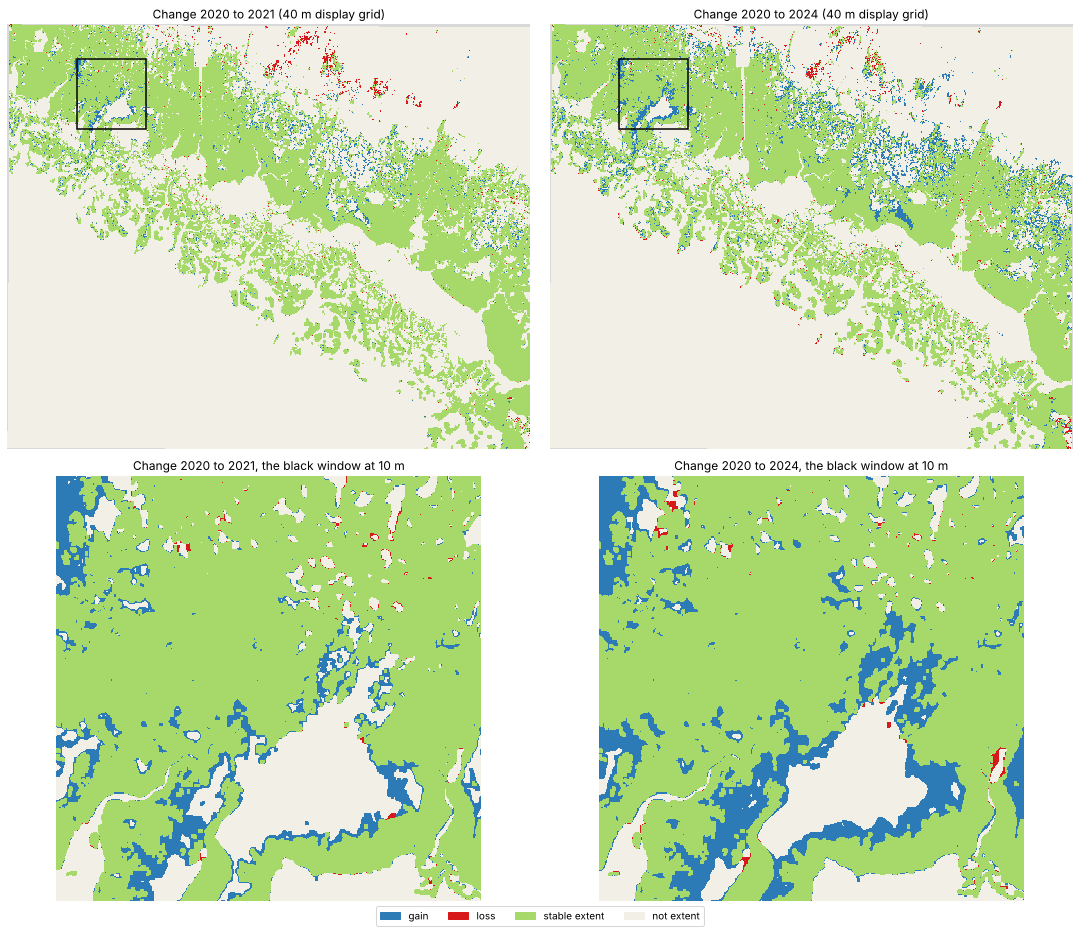

In [14]:
def change_image(ch: np.ndarray, ea: np.ndarray) -> np.ndarray:
    """0 not extent, 1 loss, 2 gain, 3 stable extent; NaN not classified."""
    out = np.where(np.isfinite(ch), 0.0, np.nan)
    out[ch == -1], out[ch == 1] = 1, 2
    out[(ch == 0) & ea] = 3
    return out


CH_CMAP = ListedColormap(["#f2f0e6", "#d7191c", "#2c7bb6", "#a6d96a"]).with_extremes(bad=GREY)
ch24 = change_image(B["change"], ext[YEAR_A])
ch21 = change_image(B21["change"], B21[f"extent_{YEAR_A}"] == 1)
fig, axes = plt.subplots(2, 2, figsize=(15, 12.5), layout="constrained")
for col, (img, label) in enumerate(((ch21, "2020 to 2021"), (ch24, "2020 to 2024"))):
    axes[0, col].imshow(img[::STEP, ::STEP], cmap=CH_CMAP, vmin=-0.5, vmax=3.5, extent=EXTENT, interpolation="nearest")
    axes[0, col].add_patch(Rectangle((x0, y0), 4000, 4000, fill=False, ec="k", lw=1.5))
    axes[0, col].set_title(f"Change {label} (40 m display grid)")
    axes[1, col].imshow(img[zr : zr + 400, zc : zc + 400], cmap=CH_CMAP, vmin=-0.5, vmax=3.5, interpolation="nearest")
    axes[1, col].set_title(f"Change {label}, the black window at 10 m")
for a in axes.ravel():
    a.set_axis_off()
fig.legend(
    handles=[
        Patch(color="#2c7bb6", label="gain"),
        Patch(color="#d7191c", label="loss"),
        Patch(color="#a6d96a", label="stable extent"),
        Patch(color="#f2f0e6", label="not extent"),
    ],
    loc="lower center",
    ncols=4,
    bbox_to_anchor=(0.5, -0.03),
)
plt.show()

WorldCover also maps 2021, so the 2020 to 2021 run scores both years. The two years are scored against two
product versions made with different algorithms, so the change between the two reference maps is not by itself
change on the ground.

In [15]:
v21 = s21["validation"]
display(
    pd.DataFrame(
        {
            str(y): {
                "WorldCover version": v21["version_mix"]["versions"][str(y)],
                "recall": e["recall"],
                "precision": e["precision"],
                "IoU": e["iou"],
                "F1": e["f1"],
                "WorldCover mangrove in the AOI (ha)": e["reference_pixels_in_aoi"] * io.HA_PER_PIXEL,
                "app extent (ha)": s21["extent"][str(y)]["extent_ha"],
                "false positives in water": e["false_positive_classes"].get("80", {}).get("share", 0.0),
            }
            for y, e in v21["per_year"].items()
        }
    )
)
mix = v21["version_mix"]
print(
    f"v100 and v200 agree on mangrove or not over {mix['reference_agreement']:.1%} of the "
    f"{mix['pixels_scored_both_years']:,} pixels scored in both years (class codes agree on "
    f"{mix['class_code_agreement']:.1%})"
)

,2020,2021
WorldCover version,v100,v200
recall,0.894,0.934
precision,0.94,0.934
IoU,0.846,0.876
F1,0.917,0.934
WorldCover mangrove in the AOI (ha),23979.15,23595.06
app extent (ha),22813.31,23581.58
false positives in water,0.232,0.596


v100 and v200 agree on mangrove or not over 96.3% of the 7,298,866 pixels scored in both years (class codes agree on 94.8%)


The app's 2021 extent agrees with WorldCover 2021 at least as well as its 2020 extent agrees with WorldCover 2020
(IoU 0.876 against 0.846), so the method is stable across a year. But the direction of change differs:
WorldCover's mangrove shrinks by about 380 ha from v100 to v200, while the app's extent grows by 768 ha. The two
WorldCover maps disagree on 3.7% of pixels, more than either year's change, so neither direction is established
by WorldCover. Note also that the 2021 false positives are mostly water (60%): over this AOI v200 maps about
1,170 ha of v100's mangrove as water, and only about 70 ha the other way.

Now the 2024 change. The cells below ask two questions: does the score distribution of each WorldCover class shift
between years (which moves pixels across a fixed threshold without any change on the ground), and is the gain
speckle or coherent patches?

In [16]:
groups = {
    "WorldCover 2020 mangrove (95)": wc[2020] == 95,
    "herbaceous wetland (90)": wc[2020] == 90,
    "tree cover (10)": wc[2020] == 10,
    "permanent water (80)": wc[2020] == 80,
}
cls_b = classified & np.isfinite(B21["change"]) & zp.mask
s21_score, s24_score = B21["score_2021"], B[f"score_{YEAR_B}"]
YEARS3 = ((2020, s_a), (2021, s21_score), (2024, s24_score))
drift = {}
for name, m in groups.items():
    m = m & cls_b
    drift[name] = {f"median {y}": float(np.median(s[m])) for y, s in YEARS3} | {
        f"within threshold {y}": float(np.mean(s[m] <= thr)) for y, s in YEARS3
    }
seed_b21 = pd.read_parquet(result21.extra_paths["seeds"])
drift["seed pixels"] = {
    "median 2020": float(np.median(ins)),
    "median 2021": float(seed_b21.loc[seed_b21["used"], "score_year_b"].median()),
    "median 2024": float(seed_px.loc[used, "score_year_b"].median()),
    "within threshold 2020": float(np.mean(ins <= thr)),
    "within threshold 2021": float(np.mean(seed_b21.loc[seed_b21["used"], "score_year_b"] <= thr)),
    "within threshold 2024": float(np.mean(seed_px.loc[used, "score_year_b"] <= thr)),
}
dr = pd.DataFrame(drift).T
for c in dr.columns:
    dr[c] = dr[c].map("{:.1%}".format if c.startswith("within") else "{:.3f}".format)
dr

,median 2020,median 2021,median 2024,within threshold 2020,within threshold 2021,within threshold 2024
WorldCover 2020 mangrove (95),0.102,0.107,0.123,90.0%,92.3%,94.6%
herbaceous wetland (90),0.435,0.429,0.391,7.1%,10.4%,16.8%
tree cover (10),0.362,0.372,0.362,14.1%,8.9%,14.0%
permanent water (80),0.444,0.447,0.433,1.0%,1.1%,1.2%
seed pixels,0.098,0.093,0.104,95.8%,99.4%,100.0%


In [17]:
def by_patch(m: np.ndarray) -> tuple[float, float]:
    """Hectares of a change mask in patches under 1 ha (speckle) and of 1 ha or more (coherent), 8-connected."""
    lab, _ = ndimage.label(m, structure=np.ones((3, 3)))
    sizes = np.bincount(lab.ravel())
    sizes[0] = 0
    coherent = int(sizes[sizes >= 100].sum())
    return (int(m.sum()) - coherent) * io.HA_PER_PIXEL, coherent * io.HA_PER_PIXEL


rows = {}
for label, ch, later in (("2020 to 2021", B21["change"], s21_score), ("2020 to 2024", B["change"], s24_score)):
    gain, loss = ch == 1, ch == -1
    by_class = pd.Series(wc[2020][gain]).map(lambda c: WC_NAMES.get(int(c), str(c))).value_counts(normalize=True)
    (gs, gc), (ls, lc) = by_patch(gain), by_patch(loss)
    rows[label] = {
        "gain in patches under 1 ha (ha)": f"{gs:,.0f}",
        "gain in patches of 1 ha or more (ha)": f"{gc:,.0f}",
        "loss in patches under 1 ha (ha)": f"{ls:,.0f}",
        "loss in patches of 1 ha or more (ha)": f"{lc:,.0f}",
        "gain: WorldCover 2020 class": ", ".join(f"{k} {v:.0%}" for k, v in by_class.head(3).items()),
        "gain: 2020 score within 0.05 of the threshold": f"{np.mean(s_a[gain] <= thr + 0.05):.0%}",
        "loss: later score within 0.05 of the threshold": f"{np.mean(later[loss] <= thr + 0.05):.0%}",
    }
pd.DataFrame(rows)

,2020 to 2021,2020 to 2024
gain in patches under 1 ha (ha),813,947
gain in patches of 1 ha or more (ha),308,"1,579"
loss in patches under 1 ha (ha),226,272
loss in patches of 1 ha or more (ha),127,88
gain: WorldCover 2020 class,"mangroves 62%, herbaceous wetland 31%, permanent water bodies 4%","mangroves 52%, herbaceous wetland 38%, tree cover 6%"
gain: 2020 score within 0.05 of the threshold,75%,56%
loss: later score within 0.05 of the threshold,97%,88%


Speckle and coherent change behave differently, so the cell below looks at two places where the cause can be
separated: herbaceous wetland by its distance from mangrove (spread at the marsh edge should be near mangrove, a
shift of the whole year everywhere), and the largest blocks the app missed in 2020.

In [18]:
bands = {"within 100 m": (0, 100), "100 m to 1 km": (100, 1000), "over 1 km": (1000, np.inf)}
rows = {}
for code_, name in ((90, "herbaceous wetland"), (10, "tree cover"), (80, "water")):
    for band, (lo, hi) in bands.items():
        m = cls_b & (wc[2020] == code_) & (d_out > lo) & (d_out <= hi)
        if m.sum() < 10_000:
            continue
        rows[f"{name}, {band} of mangrove"] = (
            {"pixels": f"{m.sum():,}"}
            | {f"median {y}": f"{np.median(s[m]):.3f}" for y, s in YEARS3}
            | {f"within threshold {y}": f"{np.mean(s[m] <= thr):.1%}" for y, s in YEARS3}
        )
display(pd.DataFrame(rows).T)

order = np.argsort(miss_sizes)[::-1][:5]
display(
    pd.DataFrame(
        [
            {
                "missed block (ha)": miss_sizes[k] * io.HA_PER_PIXEL,
                "median score 2020": float(np.median(s_a[miss_lab == k])),
                "median score 2021": float(np.median(s21_score[miss_lab == k])),
                "median score 2024": float(np.median(s24_score[miss_lab == k])),
                "extent in 2021": float(np.mean(B21["extent_2021"][miss_lab == k] == 1)),
                "extent in 2024": float(np.mean(ext[YEAR_B][miss_lab == k])),
            }
            for k in order
        ]
    )
)
print(
    f"of all 2020 misses, extent in 2021: {np.mean(B21['extent_2021'][fn] == 1):.1%}; "
    f"in 2024: {np.mean(ext[YEAR_B][fn]):.1%}"
)

,pixels,median 2020,median 2021,median 2024,within threshold 2020,within threshold 2021,within threshold 2024
"herbaceous wetland, within 100 m of mangrove","344,744",0.390,0.363,0.323,16.3%,25.2%,39.8%
"herbaceous wetland, 100 m to 1 km of mangrove","270,539",0.431,0.428,0.380,3.9%,4.7%,7.7%
"herbaceous wetland, over 1 km of mangrove","352,085",0.535,0.544,0.500,0.5%,0.3%,1.3%
"tree cover, within 100 m of mangrove","16,405",0.219,0.190,0.174,76.1%,79.5%,78.3%
"tree cover, 100 m to 1 km of mangrove","38,389",0.333,0.341,0.340,27.8%,20.3%,21.5%
"tree cover, over 1 km of mangrove","386,945",0.367,0.376,0.366,10.1%,4.8%,10.6%
"water, within 100 m of mangrove","705,022",0.405,0.415,0.398,4.7%,4.9%,5.5%
"water, 100 m to 1 km of mangrove","921,862",0.411,0.419,0.400,0.3%,0.3%,0.3%
"water, over 1 km of mangrove","1,843,529",0.484,0.472,0.468,0.0%,0.0%,0.0%


,missed block (ha),median score 2020,median score 2021,median score 2024,extent in 2021,extent in 2024
0,296.39,0.444,0.385,0.219,0.296,0.575
1,129.65,0.406,0.334,0.171,0.335,0.778
2,50.35,0.392,0.441,0.399,0.031,0.228
3,41.43,0.382,0.186,0.121,0.803,0.902
4,28.78,0.418,0.342,0.150,0.391,0.727


of all 2020 misses, extent in 2021: 27.1%; in 2024: 51.8%


An honest reading of the 2020 to 2024 change:

- **Loss is at the noise floor.** Four years of loss (360 ha) is no more than one year of loss (353 ha), most of it
  is speckle, and 88% of the loss pixels end within 0.05 of the threshold. So the app detects no mangrove loss from
  Ian in this AOI above its own flicker. That does not prove there was none: damage that leaves a stand seed-like
  at 10 m, or loss north of the AOI where Ian came ashore, would not show here.
- **Speckled gain is flicker.** Gain in patches under 1 ha is about the same after one year (813 ha) as after four
  (947 ha). That is the threshold noise of two separate classifications, not change.
- **Coherent gain grows with time.** Gain in patches of 1 ha or more is 308 ha after one year and 1,579 ha after
  four. About half the gain lies inside stands WorldCover already mapped as mangrove in 2020, largely the big blocks
  the app missed then: four of the five largest have median scores that fall year after year (the largest from
  0.444 in 2020 to 0.385 in 2021 and 0.219 in 2024), and about half of all 2020 misses are extent by 2024. That
  looks like stands still damaged in 2020, three years after Irma, regrowing; WorldCover, a land cover map, labels
  a damaged stand mangrove all along.
  Most of the rest is herbaceous wetland beside mangrove: marsh within 100 m of mangrove moves toward the seeds
  about twice as far as marsh more than 1 km away, and its share under the threshold goes from 16% to 40%, which
  fits mangrove spreading at the marsh edge.
- **But 2024 also sits a little differently.** Marsh more than 1 km from any mangrove, where spread within four
  years is implausible, scores about 0.035 lower in 2024 than in 2020, and water a little lower too, while tree
  cover does not move. A fixed threshold carried across years turns such a shift into gain at the margins, so part
  of even the coherent gain at the marsh edge may be this.

**Verdict.** Of the net gain of 2,166 ha (+9.5%), about 950 ha is threshold flicker (it appears after one year as
well) and about 1,600 ha is spatially coherent change that behaves like recovery and spread at the marsh edge, with
some year-to-year shift mixed in. Treat the 1,600 ha as an upper bound on real gain, report it with the one-year
comparison next to it, and confirm it against an independent annual reference (GMW v4.1.12 is annual 1985 to 2025,
`--reference-source gmw --gmw-version v4.1.12`) or imagery before using it.

## 7. Coastal fraction

The brief asks for the fraction of the extent within 1 km of the coastline. With no `--shoreline`, the app uses
the Natural Earth 10 m coastline, which is approximate here: its segments around the AOI have a median length of
about 0.9 km, the same scale as the buffer (survey N9). It draws the mainland shore and three generalised outlines of
island groups, not the individual islands or the creeks, so "coastal" here means near that generalised line.

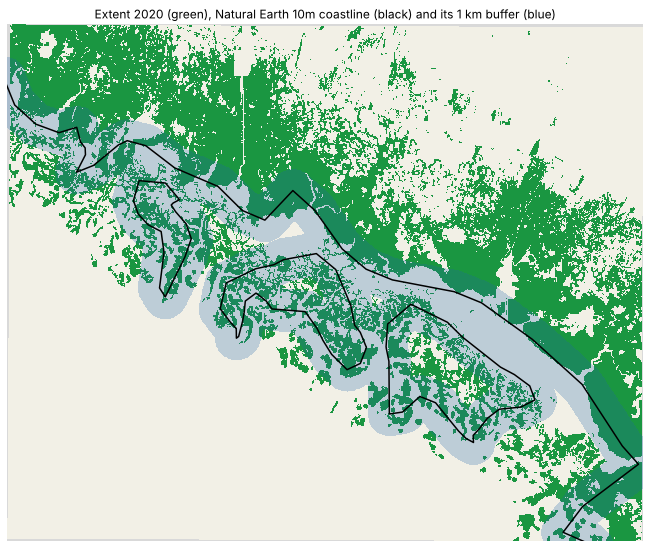

4 lines, 111.6 km, median segment 930 m; approximate: True
coastal fraction within 1 km: 35.8% in 2020, 34.3% in 2024
sensitivity to the buffer, 2020: 0.5 km 20.1%, 1 km 35.8%, 2 km 57.9%


In [19]:
coast = summary["coastal"]
west, south, east, north = aoi.geometry.bounds
lines = validate.natural_earth_coastline((west - 0.03, south - 0.03, east + 0.03, north + 0.03), scale="10m")
dist = wetland.shoreline_distance_m(zp, lines, 2000.0)
frac = {km: float((ext[YEAR_A] & (dist <= km * 1000)).sum() / ext[YEAR_A].sum()) for km in (0.5, 1.0, 2.0)}
assert abs(frac[1.0] - summary["coastal_fraction_year_a"]) < 0.002  # the app's number, recomputed

img = np.where(classified, ext[YEAR_A].astype(float), np.nan)
fig, ax = plt.subplots(figsize=(10, 7.5), layout="constrained")
ax.imshow(
    img[::STEP, ::STEP],
    cmap=ListedColormap(["#f2f0e6", "#1a9641"]).with_extremes(bad=GREY),
    extent=EXTENT,
    interpolation="nearest",
)
near = (dist <= 1000.0).astype(float)[::STEP, ::STEP]
ax.contourf(near, levels=[0.5, 1.5], colors=["#2166ac"], alpha=0.25, extent=EXTENT, origin="upper")
gpd.GeoSeries(lines, crs="EPSG:4326").to_crs(CRS).plot(ax=ax, color="k", lw=1.5)
ax.set_xlim(EXTENT[0], EXTENT[1])
ax.set_ylim(EXTENT[2], EXTENT[3])
ax.set_title(f"Extent {YEAR_A} (green), Natural Earth 10m coastline (black) and its 1 km buffer (blue)")
ax.set_axis_off()
plt.show()
print(
    f"{coast['lines']} lines, {coast['length_km']:.1f} km, median segment {coast['median_segment_m']:.0f} m; "
    f"approximate: {coast['approximate']}"
)
print(
    f"coastal fraction within 1 km: {summary['coastal_fraction_year_a']:.1%} in {YEAR_A}, "
    f"{summary['coastal_fraction_year_b']:.1%} in {YEAR_B}"
)
print("sensitivity to the buffer, 2020:", ", ".join(f"{km:g} km {f:.1%}" for km, f in frac.items()))

About a third of the mapped mangrove lies within 1 km of the Natural Earth coastline, in both years (35.8% and
34.3%). The same 2020 extent gives 20% at 0.5 km and 58% at 2 km, so the number says as much about the buffer and
the line as about the mangrove. Pass `--shoreline` with a finer line (OSM land polygons, GSHHG full resolution, or a
water edge derived from the embeddings) for a number worth comparing between sites.

## 8. Using your own seeds

The bundled seeds are a demo. For your own site, pass `--seeds` with a file of confirmed locations of the wetland
type you want:

- **Formats.** Any vector file GDAL reads (GeoJSON, GeoPackage, shapefile), in any CRS, of points or polygons; or
  a CSV with `lon` and `lat` columns (`longitude`/`latitude` or `x`/`y` also work) or a WKT geometry column. Lines
  are ignored. If the file has a `role` column, only features with `role == "seed"` count. Seeds may lie outside
  the AOI, and their zones' years are checked before any read.
- **How many.** The hard floor is 5 valid pixels (brief section 6), but a threshold needs more than that. A point is
  one pixel; a polygon is every pixel centre inside it. Aim for several hundred pixels from at least five separate
  places: points in one 2 km cell, or polygons that touch, form one spatial block, and a run with fewer than two
  blocks falls back to an in-sample threshold with a warning (pass `--fold-cell-m` smaller for a small AOI).
- **Which score.** Keep the default cosine score. `--score mahalanobis` uses a Ledoit-Wolf shrunk covariance and is
  refused below 500 valid seed pixels, before any chunk is read.
- **Another wetland type.** For salt marsh or sawgrass, use seeds of that type and validate with
  `--reference-classes 90` (WorldCover herbaceous wetland) or your own `--reference` file.

The cell below writes the centres of the 12 bundled squares as a points CSV, loads it (a CSV declares no CRS, so
lon/lat is assumed, with a warning), and shows the Mahalanobis guard refusing it: 12 points are 12 pixels.

In [20]:
points_csv = Path("out/wetland_points.csv")
pd.DataFrame({"lon": ((b.minx + b.maxx) / 2).round(6), "lat": ((b.miny + b.maxy) / 2).round(6)}).to_csv(
    points_csv, index=False
)
point_seeds = wetland.load_seeds(points_csv)
print(f"{points_csv}: {len(point_seeds.points)} points, {len(point_seeds.polygons)} polygons")
try:
    run_wetland("everglades", YEAR_A, YEAR_B, Path("out/wetland_points"), seeds=points_csv, score="mahalanobis")
except AppInputError as exc:
    print("refused before any chunk read:", exc)

WARNING tessera_apps.apps.wetland: out/wetland_points.csv declares no CRS; its coordinates look like lon/lat, so EPSG:4326 is assumed.


WARNING tessera_apps.apps.wetland: out/wetland_points.csv declares no CRS; its coordinates look like lon/lat, so EPSG:4326 is assumed.


out/wetland_points.csv: 12 points, 0 polygons


INFO tessera_apps.apps._common: wetland: AOI demo:everglades, 73,237 ha in 1 zone(s) (17N 2448 x 3015), 7,323,696 pixels; years 2020, 2024; at most 3.58 GB of chunks to read.


INFO tessera_apps.apps._common: wetland: peak memory about 1.6 GB (13.5 GB available).


refused before any chunk read: --score mahalanobis needs at least 500 valid seed pixels and the seeds cover only 12: with 128 dimensions the covariance of fewer pixels is singular or barely shrunk, and its inverse is meaningless (survey B6). Use --score cosine, or add seed polygons.


The same from a shell:

```
tessera-apps wetland --aoi my_aoi.geojson --year-a 2020 --year-b 2021 --seeds my_points.csv --validate
tessera-apps wetland --aoi my_aoi.geojson --year-a 2020 --year-b 2024 --seeds stands.gpkg --score mahalanobis
tessera-apps wetland --aoi my_aoi.geojson --year-a 2020 --year-b 2021 --seeds marsh.geojson --validate --reference-classes 90
```

Seed quality matters more than seed count: seeds that are all interior stands (as here) set a reference that edge
and creek-bank mangrove only partly matches, which is where the misses of section 5 are.

## 9. Cost

The report records bytes read and stage timings. Peak memory was measured from outside with `/usr/bin/time -v`
on the CLI run: a maximum resident set of 1.74 GB (1,700,908 KiB), about 10% above the app's own estimate of
1.58 GB. The CLI's wall time was 64 s. A rerun with the same arguments was skipped in 3.1 s and left every output
byte-identical.

In [21]:
def cost(rep: dict) -> dict[str, str]:
    """Bytes, timings and memory of one run's report, formatted."""
    t = rep["timings"]
    staged = sum(v for k, v in t.items() if k != "wall_s")
    return {
        "bytes read": f"{rep['bytes_read'] / 1e9:.2f} GB",
        "estimate (upper bound)": f"{rep['estimated_bytes'] / 1e9:.2f} GB",
        "wall": f"{t['wall_s']:.0f} s",
        "streaming": f"{t['stream']:.0f} s",
        "regime probe + seed reads": f"{t['regime_probe'] + t['seeds_read']:.0f} s",
        "write (COG, tables, preview)": f"{t['write']:.0f} s",
        "before the first chunk read (metadata, seeds, references)": f"{t['wall_s'] - staged:.0f} s",
        "memory estimate": f"{rep['estimated_memory'] / 1e9:.2f} GB",
    }


display(pd.DataFrame({"2020 to 2024": cost(report), "2020 to 2021": cost(result21.report)}))
print(f"bytes read note: {report['bytes_read_note']}")
print(
    f"this notebook: the PCA false colour read {int(cached['bytes_read']) / 1e9:.2f} GB when it was computed; "
    f"this session read {reader.bytes_read / 1e9:.3f} GB"
)

,2020 to 2024,2020 to 2021
bytes read,2.37 GB,2.37 GB
estimate (upper bound),3.80 GB,3.80 GB
wall,98 s,81 s
streaming,71 s,33 s
regime probe + seed reads,8 s,26 s
"write (COG, tables, preview)",8 s,7 s
"before the first chunk read (metadata, seeds, references)",7 s,13 s
memory estimate,1.58 GB,1.58 GB


bytes read note: Chunk payload bytes returned by the zarr store (io.CountingStore), gap bytes of merged range requests included. Icechunk manifest and snapshot fetches below the zarr interface are not counted.
this notebook: the PCA false colour read 1.06 GB when it was computed; this session read 0.000 GB


About half the wall time is streaming two years of the AOI's 132 chunks. The rest is mostly the preflight
(store metadata, placing the seeds, fetching the WorldCover window and the Natural Earth coastline, none of which
counts in bytes read, which counts store chunks only) and writing the 82 MB COG.
The AOI is small, so memory is not a concern; the app warns before any chunk read when its estimate exceeds the
memory available.

## 10. Take-aways

- **Recall against WorldCover 2020 mangrove is 0.894** (precision 0.940, IoU 0.846), with the seeds and 200 m
  around them left out, and 0.934 against WorldCover 2021. Away from a 20 m band around WorldCover's mangrove
  edges, recall is 0.931 and precision 0.969.
- **The score is not independent.** The seeds come from WorldCover, the reference they are scored against. Treat
  these numbers as a consistency check and rerun with GMW stands or field seeds where they can be reached.
- **Disagreement is mostly edges plus one real confusion.** Water and marsh false positives and most misses sit on
  stand edges; tree-cover false positives are inland woody vegetation the embeddings put near mangrove.
- **The four-year change is partly real, and the method alone cannot say how much.** One year of change (gross
  6.5% of the extent) sets a noise floor. Loss over four years does not exceed it, so no Ian loss is detected.
  Speckled gain is about the same after one year and four. Coherent gain (1,579 ha in patches of 1 ha or more, against
  308 ha after one year) grows with time and looks like regrowth of stands damaged in 2020 and spread at the marsh
  edge, with some year-to-year shift of the marsh scores mixed in.
- **Coastal fraction is approximate.** With Natural Earth it depends as much on the buffer and the generalised line
  as on the mangrove (20%, 36% and 58% at 0.5, 1 and 2 km).

What should change in the brief: validate against GMW v4.1.12 (annual, so both years) with seeds from an
independent source; and make the change step report its own noise: run an adjacent-year pair alongside, and split
gain and loss into speckle and coherent patches, before anyone reads the net change as a trend.